Implementing micrograd: backpropagation for scalar values (although conceptually and mathematically, things are the same in modern auto differentiation libraries; it's just that things are in tensors instead of scalars)

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


Review of derivatives:

In [4]:
def f(x):
    return 3*x**2 - 5*x + 3

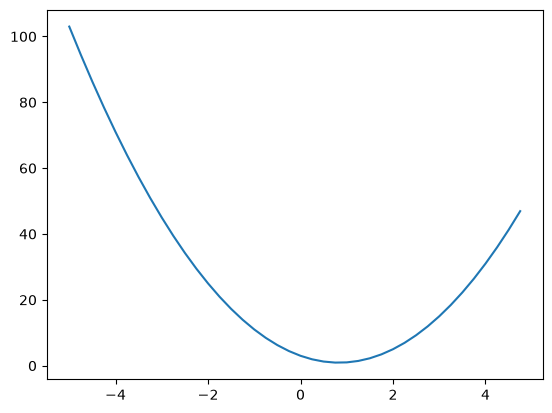

In [5]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [6]:
# definition of derivative
h = 0.00000001
x = 2/3
(f(x+h) - f(x))/h

-1.0000000161269895

In [7]:
# another example
h = 0.0000001

# inputs
a = 3.0
b = -4.0
c = 2.0

d1 = a*b + c
a += h
d2 = a*b + c

print("slope: ", (d2-d1)/h)

slope:  -3.9999999934536845


## Building the core Value object for micrograd.

### Step 0:
- Outline data structure and implement add, multiply, etc. functions

### Step 1 (_prev and _op):
- For each value, we need to know the children values that created that particular value (i.e., we need to know it "children").
- For each value, we need to know the operation that created that value.

This way, for each value, we know exactly how that value came to be: by what values being operated together, and which operation.

### Step 2 (grad):
We need grad, a variable inside the Value class, that maintains the derivative of the final output value wrt a particular value of interest (current value).

### Step 3 (_backward):
We need to implement the function that propagates the gradient. _backward function stores, for each node, how the upstream gradient (coming from final output) should be chained with the downstream gradient (going towards inputs).
Once implemented, at this point, we can manually call _backward for each computational node.

![Gradient flow](fig/backprop.png)

### Step 4 (backward):
Instead of manually calling _backward through all the computational nodes, use topological sort to sort the nodes from left to right, and then call _backwards along those sorted nodes (in reverse order).

### Step 5 (gradient accumulation):
So far, if any variable is used twice, then gradients overwrite, and we get the wrong gradients. We need to allow gradients to accumulate.

### Step 6 (some clean up):
Make it so that things like "a = Value(2.0) ; a + 1 ; 1 + a" work

In [70]:
class Value:

    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children)
        self._op =_op
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        "__repr__ is used to return a string representation of an object that can be used to essentially recreate the object using eval()"
        return f"Value(data={self.data})"

    def __add__(self, other):
        "when we use 'a + b' in python, python will internally call a.__add__(b)"
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            """
            out.grad is the upstream gradient
            We need to fill in the downstream gradients, i.e., gradients of the inputs to this computational node.
            Here, we apply chain rule, for addition.
            These functions return None.
            """
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        # just store the _backward function
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            """
            out.grad is the upstream gradient
            We need to fill in the downstream gradients, i.e. gradients of the inputs to this computational node.
            Here, we apply the chain rule, for multiplication.
            These functions return None.
            """
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward

        return out

    def __rmul__(self, other):
        "used to define reversed multiplication"
        return self * other

    def __radd__(self, other):
        return self + other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __pow__(self, other):
        "raising integer to power"
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self, ), f"**{other}")

        def _backward():
            self.grad += out.grad * (other * self.data ** (other - 1))

        out._backward = _backward
        return out

    def __truediv__(self, other):
        "implements self / other"
        return self * other**-1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), "exp")

        def _backward():
            self.grad += out.data * out.grad
            
        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), "tanh")

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                # only append current value to the topological list once all its children nodes have been added
                topo.append(v)
        
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

Dummy example:

In [71]:
a = Value(2.0)
b = Value (-3.0)
c = Value(10.0)
d = a*b + c

In [72]:
d.backward()

print("dd/dc: ", c.grad)
print("dd/db: ", b.grad)
print("dd/da: ", a.grad)

dd/dc:  1.0
dd/db:  2.0
dd/da:  -3.0


Example that requires gradient accumulation:
- In the above examples, each variable was only used once. In the following case, the variable a, for example, is used twice: in c = a * b, and in d = a * b.
- In the original code, there was a bug where inside the backward implementation we SET gradients, instead of accumulating gradients: e.g., self.grad = out.grad * other.data
- This creates a problem when we call e.backward(). The backward pass triggers calling ._backward() at each computational node. For example, at c._backward(), the gradient is set for a, but then later on when d._backward() is called, the gradient is overwritten for a and set again at another value.
- According to the multivariate chain rule, these gradients need to ACCUMULATE:
    - If z = f(x, y), where x = g(t) and y = h(t) depend on a single independent variable t, the total derivative of z with respect to t is: dz/dt = df/dx * dx/dt + df/dy * dy/dt
    - You sum the products of the partial derivatives of f with respect to each intermediate variable, multiplied by the derivative of that intermediate variable with respect to t.
    - So in this example, to compute a.grad (for e.backward()), we would do: de/dc * dc/da + de/dd * dd/da
    - Notice, how we add, and these gradients accumulate.
- This is why we implement gradients as: e.g., self.grad += out.grad * other.data
- This is ok, because we initialize a value's grad to 0. So they accumulate starting from zero.

In [73]:
a = Value(-2.0)
b = Value(3.0)
c = a + b
d = a * b
e = c * d

e.backward()

b.grad

-8.0

Implementations of local derivatives can be as atomic (e.g., +, -) or as abstract (e.g. tanh) as we want; the most important thing is we know the local derivative:

In [74]:
# cross-checking backpropagation
x = Value(2.0)
e = (2*x).exp()
y1 = (e - 1) / (e + 1)
y1.backward()
print(x.grad)

# clear gradient first
x.grad = 0.0
y2 = x.tanh()
y2.backward()
print(x.grad)

0.07065082485316435
0.07065082485316443


Micrograd is a scalar-valued automatic differentiation library, meaning all values are scalars. PyTorch is similar, except all values are tensors (i.e., n-dimensional arrays of scalars). But the same logic applies.

In [75]:
import torch
import random

In [76]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


MLP example with micrograd:

In [86]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        """
        Yhis function allows us to do something like this in python: n = Neuron(2) ; x = 3 ; n(3)
        We need to define w * x + b here
        """
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out= act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [87]:
x = [2.0, 3.0, 4.0]
mlp = MLP(3, [4, 5, 1])
y = mlp(x)
print(y)

Value(data=-0.6367048565436607)


A small binary classification example - training a neural network with backpropagation and gradient descent:

In [88]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

You can check number of parameters

In [89]:
len(mlp.parameters())

47

You can also check a value of a specific weight and also its gradient with respect to the output or loss or whatever.

In [90]:
mlp.layers[0].neurons[0].w[0].data

0.6384930508197415

In [91]:
mlp.layers[0].neurons[0].w[0].grad

0.0

Training loop:

In [ ]:
for k in range(20):
    # forward pass
    ypred = [mlp(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    # backward pass
    for p in mlp.parameters():
        p.grad = 0.0 # must zero all the gradients, otherwise they accumulate each time in the training loop
    loss.backward()

    # update
    for p in mlp.parameters():
        p.data += -0.1 * p.grad

    print(k, loss.data)

0 5.599803871775989
1 3.375644911802577
2 2.7748876423119597
3 2.464247202270245
4 2.03660892830315
5 2.961451787010001
6 0.30872661409474406
7 0.17115636385326713
8 0.11864748713308482
9 0.09043168323591418
10 0.07278540047123137
11 0.06072643598685111
12 0.05197958192814378
13 0.04535573610795383
14 0.04017277788010934
15 0.03601155490628044
16 0.03260045226290327
17 0.02975583975006945
18 0.027349191128355765
19 0.02528790886643108


In [95]:
ypred

[Value(data=0.9224808614634227),
 Value(data=-0.9577602968464941),
 Value(data=-0.9007771352727559),
 Value(data=0.9125395939879036)]